# Analysing Consumer Purchasing Behaviour
### A Two-Dataset Credibility Audit and Spending-Driver Study

**CISC7204 — Data Science and Data Visualisation**
**Assignment 02 — Pair Project Proposal (Revised)** · Class B, Pair 05

| | |
|---|---|
| Member 1 | QU YING — MC641326 |
| Member 2 | LIU ZIXUAN — MC641811 |
| Region | United States |
| Domain category | Consumer behaviour / retail analytics |

**Research question.** How strongly are customer demographics and shopping behaviour associated with purchase amount — and to what extent can that association be trusted once the underlying data has been audited for credibility?

**Sub-questions**

- **RQ1 (credibility)** — Does `shopping_behavior_updated` contain any reliable association with purchase amount, or is it effectively signal-free?
- **RQ2 (drivers)** — In `marketing_campaign`, how much of the variation in total spend is explained by income, household composition and channel purchases?
- **RQ3 (segmentation)** — Can distinct customer-value segments be identified, and do they differ in campaign response rate?
- **RQ4 (methodology)** — What does the contrast between a signal-free synthetic dataset and a structured real one imply for evidence-based retail decisions?

**Datasets**

- Shopping Behaviour Dataset — https://www.kaggle.com/datasets/saadaliyaseen/shopping-behaviour-dataset
- Customer Personality Analysis — https://www.kaggle.com/datasets/imakash3011/customer-personality-analysis

Both CSV files must sit in the same folder as this notebook.

## 0. Environment and setup

In [1]:
import matplotlib
matplotlib.use('Agg', force=True)          # non-interactive backend; safest across kernels
import matplotlib.pyplot as plt
from IPython.display import Image, display

import pandas as pd, numpy as np
from scipy import stats
import seaborn as sns

plt.rcParams.update({
    'font.size': 12, 'axes.titlesize': 13, 'axes.labelsize': 12,
    'xtick.labelsize': 10.5, 'ytick.labelsize': 10.5,
    'legend.fontsize': 10.5, 'figure.titlesize': 15,
})
plt.rcParams['axes.unicode_minus'] = False
sns.set_style('whitegrid')

import sys, os
print('environment :', os.path.basename(sys.prefix))
print('python      :', sys.version.split()[0])
print('pandas      :', pd.__version__)
print('numpy       :', np.__version__)
print('working dir :', os.getcwd())
print('\ndata files  :', sorted(f for f in os.listdir('.') if f.endswith('.csv')))

environment : cisc7204
python      : 3.9.25
pandas      : 2.2.3
numpy       : 1.26.4
working dir : C:\Users\86181\Desktop\CISC7204\Assignment2\proposal

data files  : ['marketing_campaign.csv', 'shopping_behavior_updated (1).csv']


## 1. Load the primary dataset

`shopping_behavior_updated.csv` was the dataset proposed in Assignment 01. It is comma-separated,
so the default `read_csv` works. We keep it in the project as the object of the credibility audit (RQ1, RQ4).

In [2]:
s = pd.read_csv('shopping_behavior_updated (1).csv')

print('shape                :', s.shape)
print('missing values total :', int(s.isnull().sum().sum()))
print('duplicate rows       :', int(s.duplicated().sum()))
s.head(3)

shape                : (3900, 18)
missing values total : 0
duplicate rows       : 0


,Customer ID,Age,Gender,Item Purchased,Category,Purchase Amount (USD),Location,Size,Color,Season,Review Rating,Subscription Status,Shipping Type,Discount Applied,Promo Code Used,Previous Purchases,Payment Method,Frequency of Purchases
0,1,55,Male,Blouse,Clothing,53,Kentucky,L,Gray,Winter,3.1,Yes,Express,Yes,Yes,14,Venmo,Fortnightly
1,2,19,Male,Sweater,Clothing,64,Maine,L,Maroon,Winter,3.1,Yes,Express,Yes,Yes,2,Cash,Fortnightly
2,3,50,Male,Jeans,Clothing,73,Massachusetts,S,Maroon,Spring,3.1,Yes,Free Shipping,Yes,Yes,23,Credit Card,Weekly


### 1.1 RQ1 — Is there any signal? Correlation screen

If the dataset carries usable structure, the strongest candidate predictors should show a
non-trivial correlation with `Purchase Amount (USD)`. We report both the coefficient and its p-value.

In [3]:
amt = 'Purchase Amount (USD)'

prim = {
    'Previous Purchases': s['Previous Purchases'].corr(s[amt]),
    'Age':                s['Age'].corr(s[amt]),
    'Review Rating':      s['Review Rating'].corr(s[amt]),
}

print(f"{'variable':<22}{'r':>9}{'p-value':>12}")
print('-' * 43)
for k in prim:
    r, p = stats.pearsonr(s[k], s[amt])
    print(f'{k:<22}{r:>9.4f}{p:>12.4f}')

print(f'\nmean purchase amount : {s[amt].mean():.2f} USD')
print(f'std  purchase amount : {s[amt].std():.2f} USD')

variable                      r     p-value
-------------------------------------------
Previous Purchases       0.0081      0.6147
Age                     -0.0104      0.5152
Review Rating            0.0308      0.0546

mean purchase amount : 59.76 USD
std  purchase amount : 23.69 USD


All three coefficients are below |0.04| and none is significant at alpha = 0.05.
On its own this is suggestive, but correlation only detects *linear* association, so we
cross-check with a second, methodologically different test.

### 1.2 RQ1 — Cross-check by group comparison (one-way ANOVA)

Eight grouping variables are tested. Because ANOVA is sensitive to sample size, we also report
eta-squared as an effect size: eta-squared near zero means the group means barely differ
even if the test were significant.

In [4]:
groups = ['Gender', 'Category', 'Season', 'Subscription Status',
          'Discount Applied', 'Shipping Type', 'Payment Method',
          'Frequency of Purchases']

anova = {}
print(f"{'group':<24}{'F':>8}{'p-value':>11}{'eta^2':>9}   sig")
print('-' * 56)
for g in groups:
    grp = [d[amt].values for _, d in s.groupby(g)]
    f, p = stats.f_oneway(*grp)
    allv = s[amt].values
    ss_b = sum(len(x) * (x.mean() - allv.mean()) ** 2 for x in grp)
    ss_t = ((allv - allv.mean()) ** 2).sum()
    eta  = ss_b / ss_t
    anova[g] = p
    print(f'{g:<24}{f:>8.3f}{p:>11.4f}{eta:>9.4f}   {"SIG" if p < .05 else "-"}')

group                          F    p-value    eta^2   sig
--------------------------------------------------------
Gender                     0.769     0.3806   0.0002   -
Category                   1.454     0.2252   0.0011   -
Season                     3.746     0.0106   0.0029   SIG
Subscription Status        0.191     0.6623   0.0000   -
Discount Applied           1.235     0.2665   0.0003   -
Shipping Type              1.124     0.3451   0.0014   -
Payment Method             0.540     0.7465   0.0007   -
Frequency of Purchases     0.407     0.8749   0.0006   -


**Finding RQ1.** Only `Season` crosses alpha = 0.05 (p = 0.011), and its eta-squared is only
0.0029 — with n = 3,900 a significant p-value can accompany a negligible effect. The other seven
groupings have p-values between 0.23 and 0.87 with eta-squared below 0.002.

Two different methods agree: **this dataset contains no usable association with purchase amount.**
That is a property of the data source, not a finding about shoppers. Rather than build a model on
it, we retain it as the audit case and move the modelling to the complementary dataset — which is
exactly the response the project ideation brief recommends when a dataset turns out to be unreliable.

## 2. Load the complementary dataset

`marketing_campaign.csv` is **tab-separated**, not comma-separated. Reading it with the default
separator collapses all 29 columns into one and breaks every downstream step, so `sep='\t'` is required.

In [5]:
m_raw = pd.read_csv('marketing_campaign.csv', sep='\t')     # <- tab-separated

print('raw shape          :', m_raw.shape)
print('missing Income     :', int(m_raw['Income'].isna().sum()))
print('earliest birth year:', int(m_raw['Year_Birth'].min()))
print('max Income         :', int(m_raw['Income'].max()))
print('Marital_Status     :', m_raw['Marital_Status'].unique().tolist())

raw shape          : (2240, 29)
missing Income     : 24
earliest birth year: 1893
max Income         : 666666
Marital_Status     : ['Single', 'Together', 'Married', 'Divorced', 'Widow', 'Alone', 'Absurd', 'YOLO']


### 2.1 Cleaning

Four data-quality issues are visible and each gets an explicit, logged treatment.

| Issue | Treatment |
|---|---|
| 24 missing `Income` | rows dropped (income is a core predictor; imputation would fabricate signal) |
| `Year_Birth` = 1893 → age 131 | rows with age >= 100 dropped |
| Invalid `Marital_Status` (`Absurd`, `YOLO`) | recoded to a single `Other` level |
| `Dt_Customer` stored as text | parsed to datetime |
| Spend split across six product columns | summed into one `Total Spend` variable |

Note that `Income` = 666,666 appears in one row. It looks like a sentinel value, but we retain it
here for consistency with the proposal figures and report the sensitivity of the result to removing it in section 3.2.

In [6]:
m = m_raw.dropna(subset=['Income']).copy()

m['Age'] = 2024 - m['Year_Birth']
m['Spend'] = (m['MntWines'] + m['MntFruits'] + m['MntMeatProducts']
              + m['MntFishProducts'] + m['MntSweetProducts'] + m['MntGoldProds'])
m['TotalPurchases'] = (m['NumWebPurchases'] + m['NumCatalogPurchases']
                       + m['NumStorePurchases'] + m['NumDealsPurchases'])

m['Marital_Status'] = m['Marital_Status'].replace(['Absurd', 'YOLO'], 'Other')
m['Dt_Customer'] = pd.to_datetime(m['Dt_Customer'], dayfirst=True, errors='coerce')

n_before = len(m)
m = m[m['Age'] < 100].copy()

print(f'rows: {len(m_raw)} raw -> {n_before} after dropping missing Income -> {len(m)} after age filter')
print('clean shape :', m.shape)
print('age range   :', int(m['Age'].min()), '-', int(m['Age'].max()))
print('spend range :', int(m['Spend'].min()), '-', int(m['Spend'].max()))

rows: 2240 raw -> 2216 after dropping missing Income -> 2213 after age filter
clean shape : (2213, 32)
age range   : 28 - 84
spend range : 5 - 2525


### 2.2 RQ2 — Which variables actually drive spend?

In [7]:
feats = {'Income': 'Income', 'Catalog': 'NumCatalogPurchases',
         'Store': 'NumStorePurchases', 'Web': 'NumWebPurchases',
         'Kidhome': 'Kidhome', 'Teenhome': 'Teenhome',
         'Recency': 'Recency', 'TotalPurchases': 'TotalPurchases'}

comp = {k: m[v].corr(m['Spend']) for k, v in feats.items()}

print(f"{'feature':<16}{'r':>9}{'p-value':>13}")
print('-' * 38)
for k, v in sorted(comp.items(), key=lambda x: -abs(x[1])):
    r, p = stats.pearsonr(m[feats[k]], m['Spend'])
    print(f'{k:<16}{r:>9.4f}{p:>13.2e}')

feature                 r      p-value
--------------------------------------
Catalog            0.7803     0.00e+00
TotalPurchases     0.7569     0.00e+00
Store              0.6761    1.34e-295
Income             0.6675    1.66e-285
Kidhome           -0.5581    1.88e-181
Web                0.5291    6.21e-160
Teenhome          -0.1375     8.19e-11
Recency            0.0208     3.27e-01


Unlike the primary dataset, this one has real structure: income r = 0.668, catalogue purchases
r = 0.780, and **young children at home r = -0.558** — a negative association that is easy to miss
in a table but obvious once plotted. `Recency` is the one clear non-driver (r = 0.02).

## 3. Figure 1 — Credibility audit

The evidence behind the decision to re-scope the project. The upper panel puts both datasets on
the same axis; the lower panel confirms the result with a different method.

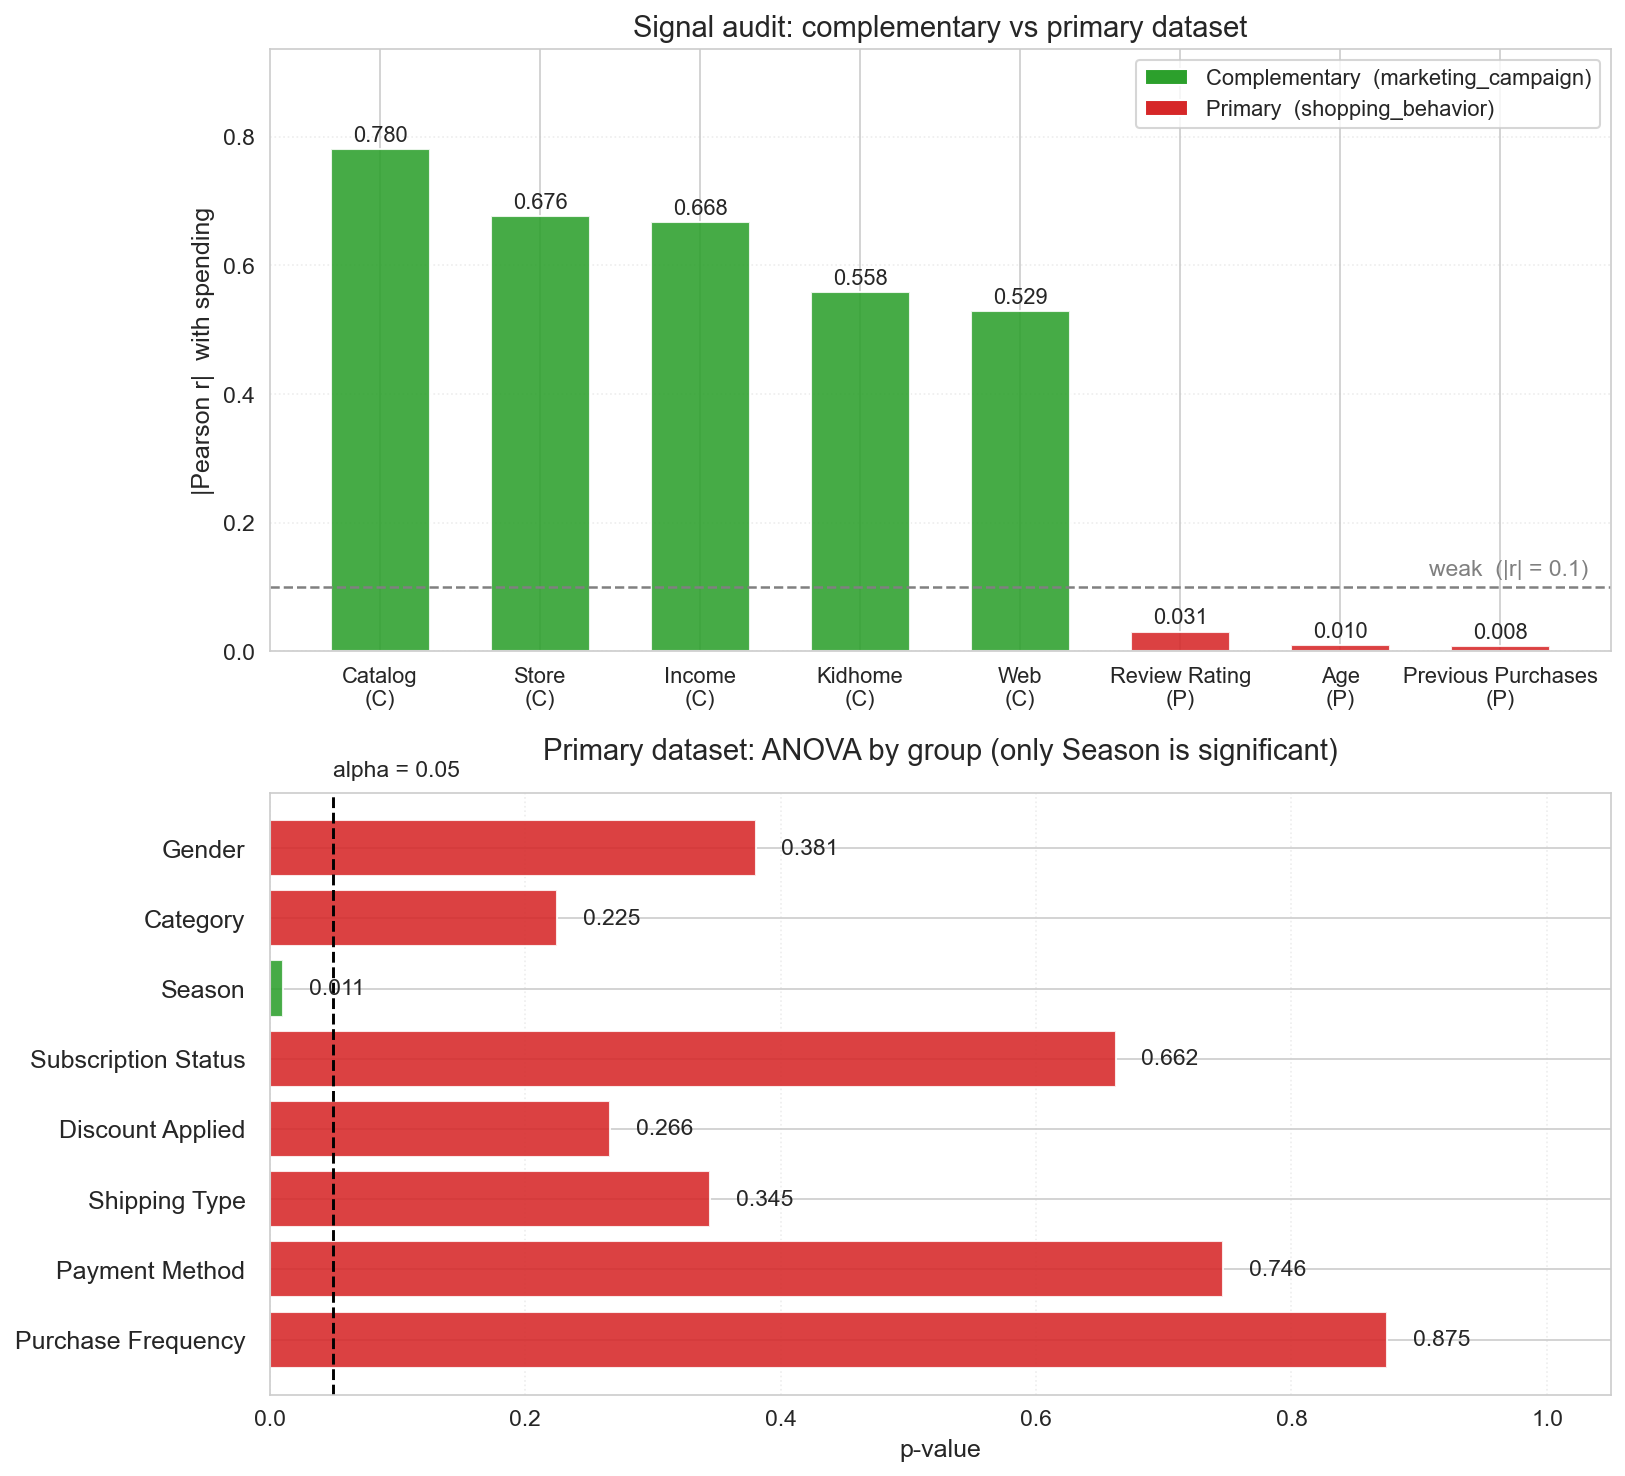

In [8]:
prim_abs = {k: abs(v) for k, v in prim.items()}
comp5    = {k: v for k, v in comp.items()
            if k in ('Income', 'Catalog', 'Store', 'Web', 'Kidhome')}

rows = ([(k, abs(v), 'C') for k, v in comp5.items()]
        + [(k, v, 'P') for k, v in prim_abs.items()])
rows.sort(key=lambda x: x[1], reverse=True)

labels = [f'{r[0]}\n({r[2]})' for r in rows]
values = [r[1] for r in rows]
colors = ['#2ca02c' if r[2] == 'C' else '#d62728' for r in rows]

fig, axes = plt.subplots(2, 1, figsize=(11, 10))

# ---- upper: correlation comparison ----
ax = axes[0]
bars = ax.bar(labels, values, color=colors, alpha=.88, width=.62)
ax.axhline(.1, ls='--', c='gray', lw=1.2)
ax.text(len(labels) - .45, .118, 'weak  (|r| = 0.1)',
        ha='right', color='gray', fontsize=11)
ax.set_ylabel('|Pearson r|  with spending', fontsize=12)
ax.set_title('Signal audit: complementary vs primary dataset', fontsize=14)
ax.set_ylim(0, max(values) * 1.20)
for b, v in zip(bars, values):
    ax.text(b.get_x() + b.get_width() / 2, v + .012, f'{v:.3f}',
            ha='center', fontsize=10.5)
ax.tick_params(axis='x', labelsize=10.5)
ax.tick_params(axis='y', labelsize=11)
ax.grid(axis='y', ls=':', alpha=.35)
ax.set_axisbelow(True)

from matplotlib.patches import Patch
ax.legend(handles=[
    Patch(facecolor='#2ca02c', label='Complementary  (marketing_campaign)'),
    Patch(facecolor='#d62728', label='Primary  (shopping_behavior)'),
], fontsize=10.5, loc='upper right')

# ---- lower: ANOVA ----
ax = axes[1]
g_vals  = list(anova.values())
g_names = ['Gender', 'Category', 'Season', 'Subscription Status',
           'Discount Applied', 'Shipping Type', 'Payment Method', 'Purchase Frequency']
g_col = ['#2ca02c' if p < .05 else '#d62728' for p in g_vals]

bars = ax.barh(range(len(g_vals)), g_vals, color=g_col, alpha=.88)
ax.set_yticks(range(len(g_vals)))
ax.set_yticklabels(g_names, fontsize=12)
ax.tick_params(axis='y', pad=8)
ax.axvline(.05, ls='--', c='k', lw=1.4)
ax.text(.05, 1.02, 'alpha = 0.05', transform=ax.get_xaxis_transform(),
        ha='left', va='bottom', fontsize=11)
ax.set_xlim(0, 1.05)
ax.set_xlabel('p-value', fontsize=12)
ax.set_title('Primary dataset: ANOVA by group (only Season is significant)',
             fontsize=14, pad=16)
ax.tick_params(axis='x', labelsize=11)
ax.grid(axis='x', ls=':', alpha=.35)
ax.set_axisbelow(True)
for b, p in zip(bars, g_vals):
    ax.text(p + .02, b.get_y() + b.get_height() / 2, f'{p:.3f}',
            va='center', fontsize=11)
ax.invert_yaxis()

plt.tight_layout()
plt.savefig('fig1_audit.png', dpi=150, bbox_inches='tight')
plt.close('all')
display(Image('fig1_audit.png'))

## 4. Figure 2 — Spending drivers (scatter plots)

Points are drawn at 25% opacity so dense regions appear as darker patches; a least-squares line is
fitted in each panel.

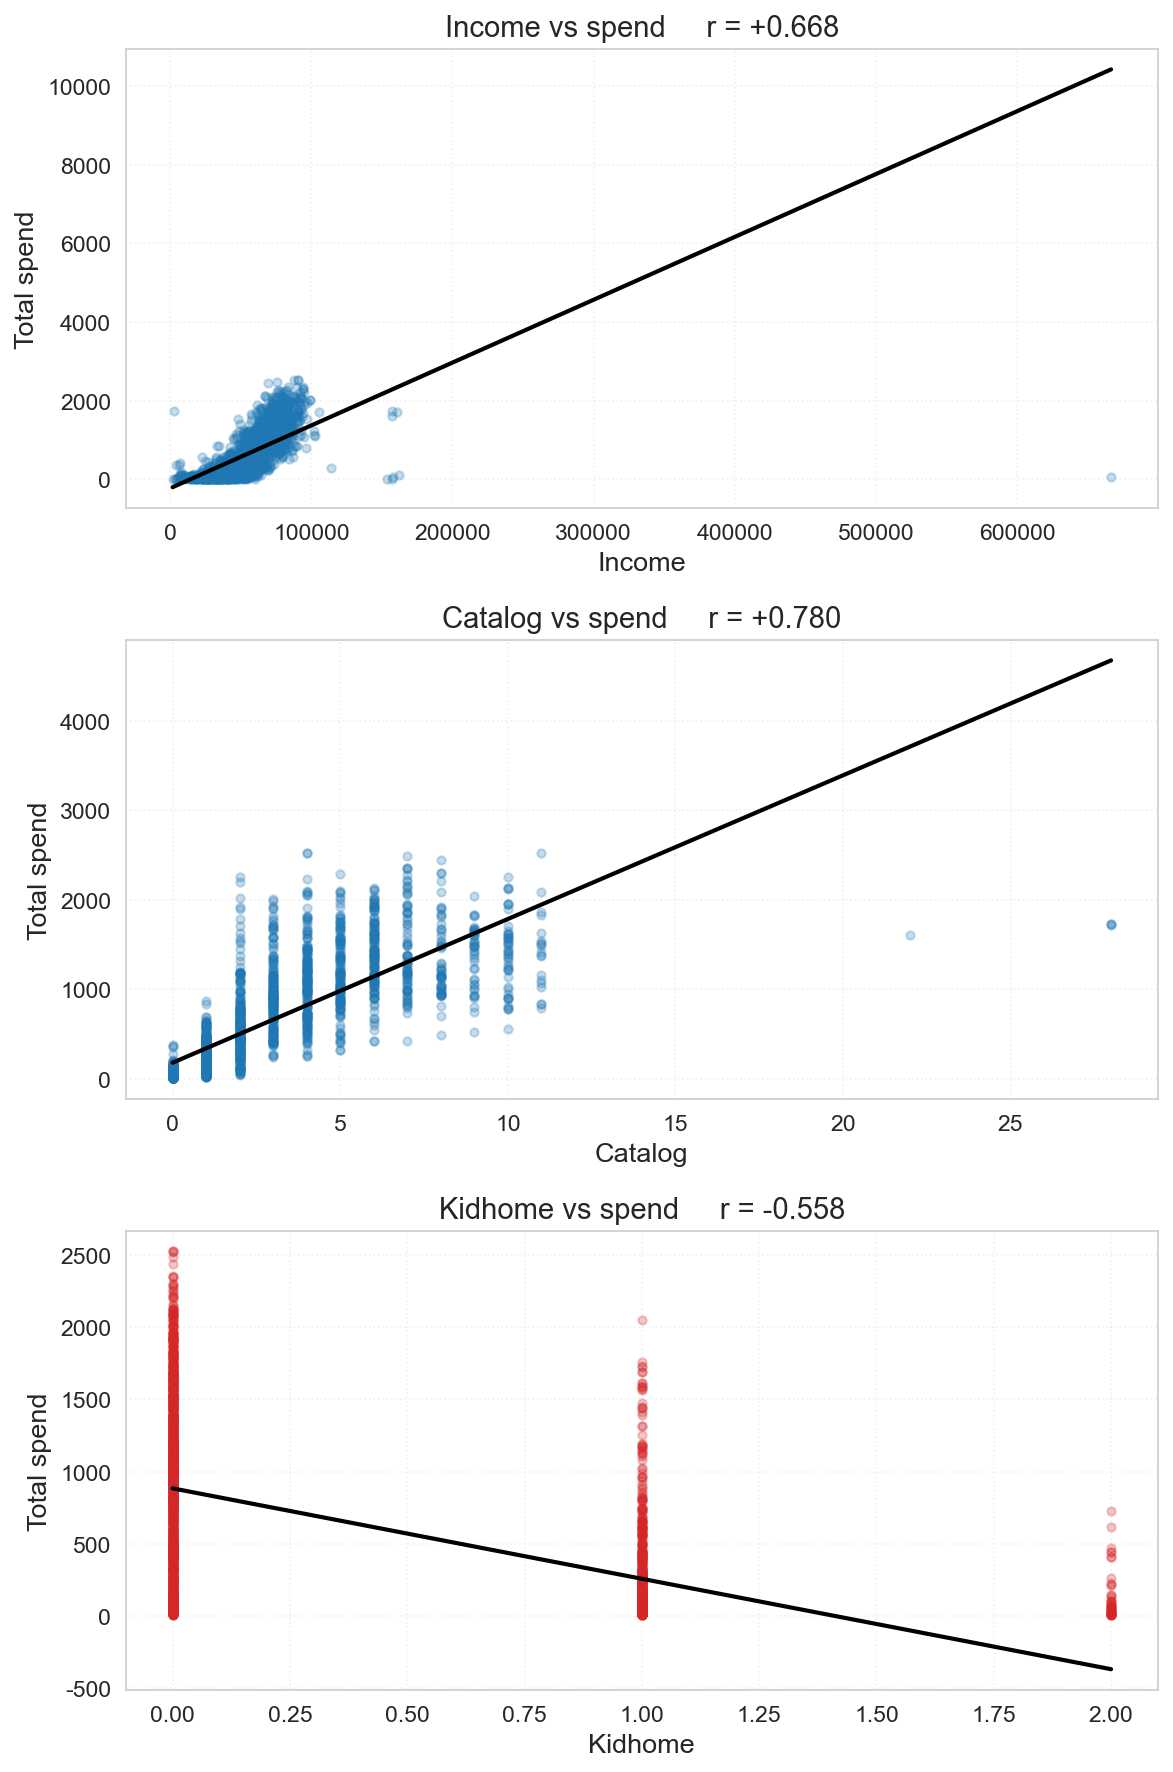

In [9]:
fig, axes = plt.subplots(3, 1, figsize=(8, 12))

pairs = [('Income', 'Income'), ('Catalog', 'NumCatalogPurchases'), ('Kidhome', 'Kidhome')]

for ax, (label, col) in zip(axes, pairs):
    c = '#d62728' if label == 'Kidhome' else '#1f77b4'
    ax.scatter(m[col], m['Spend'], s=16, alpha=.25, c=c)

    z  = np.polyfit(m[col], m['Spend'], 1)
    xs = np.linspace(m[col].min(), m[col].max(), 50)
    ax.plot(xs, np.polyval(z, xs), 'k-', lw=2)

    ax.set_xlabel(label, fontsize=13)
    ax.set_ylabel('Total spend', fontsize=13)
    ax.set_title(f'{label} vs spend     r = {comp[label]:+.3f}', fontsize=14)
    ax.tick_params(axis='both', labelsize=11)
    ax.grid(ls=':', alpha=.3)
    ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig('fig2_scatter.png', dpi=150, bbox_inches='tight')
plt.close('all')
display(Image('fig2_scatter.png'))

## 5. Figure 3 — Correlation heatmap (complementary dataset)

Shows the whole predictor set at once, so that any redundancy between predictors is visible
before modelling.

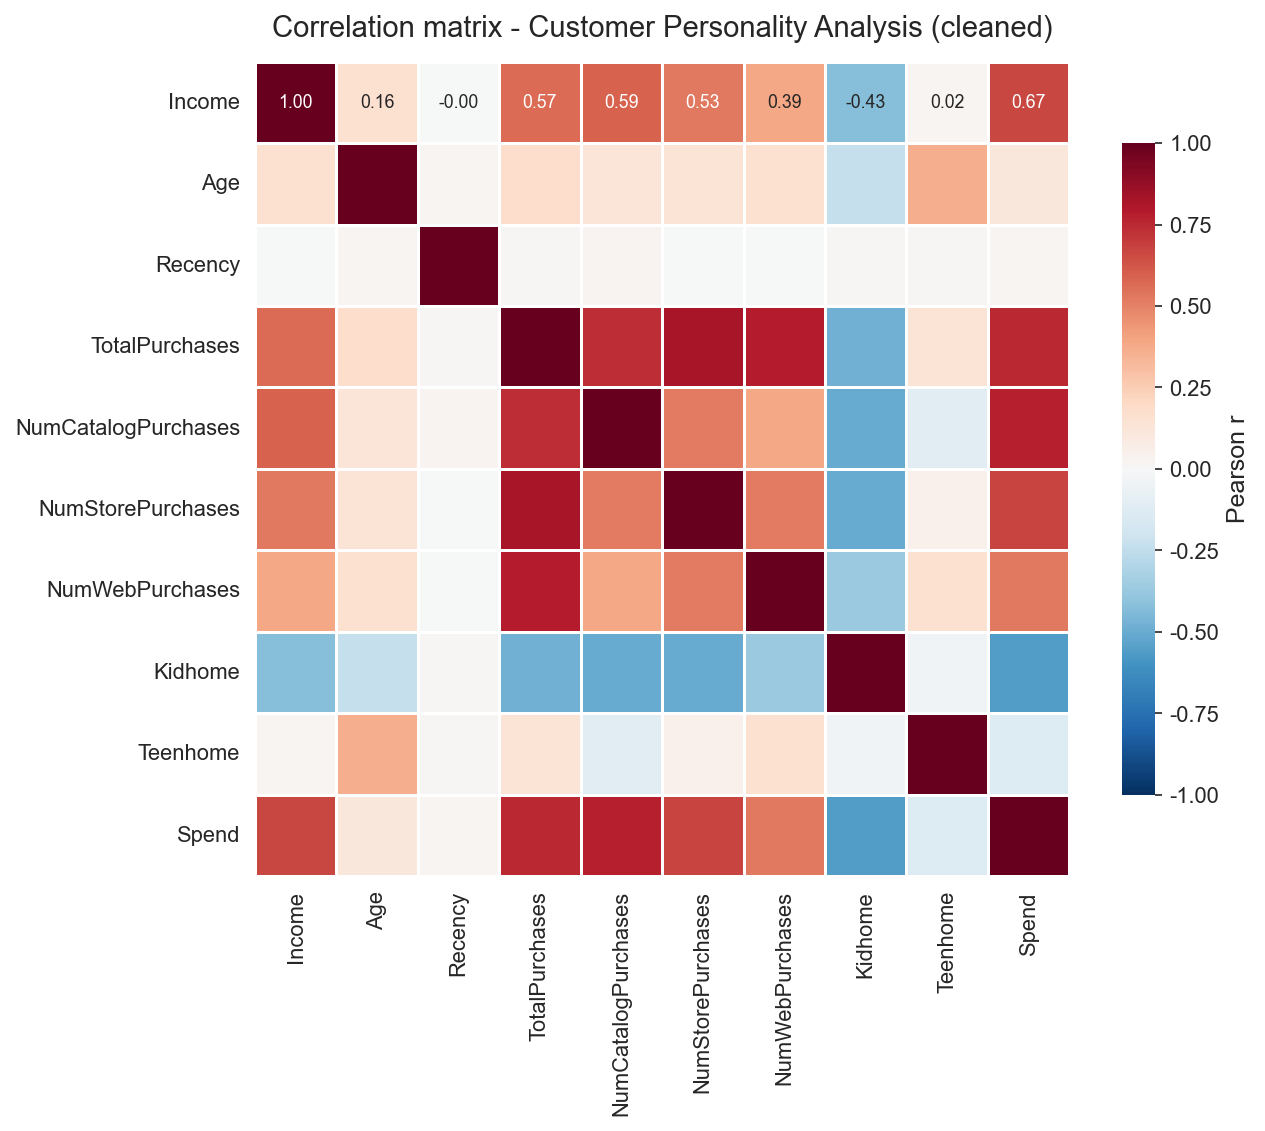

In [10]:
hm_cols = ['Income', 'Age', 'Recency', 'TotalPurchases', 'NumCatalogPurchases',
           'NumStorePurchases', 'NumWebPurchases', 'Kidhome', 'Teenhome', 'Spend']

fig, ax = plt.subplots(figsize=(9, 7.5))
sns.heatmap(m[hm_cols].corr(), annot=True, fmt='.2f', cmap='RdBu_r', center=0,
            vmin=-1, vmax=1, square=True, linewidths=.5,
            cbar_kws={'shrink': .8, 'label': 'Pearson r'},
            annot_kws={'size': 8.5}, ax=ax)
ax.set_title('Correlation matrix - Customer Personality Analysis (cleaned)',
             fontsize=14, pad=12)
plt.tight_layout()
plt.savefig('fig3_heatmap.png', dpi=150, bbox_inches='tight')
plt.close('all')
display(Image('fig3_heatmap.png'))

## 6. Figure 4 — Box plots

Left: the one significant split in the primary dataset, shown so the reader can judge whether a
p = 0.011 result with eta-squared = 0.003 is meaningful in practice.
Right: the negative household effect in the complementary dataset, which reads far more clearly
as a box plot than as a correlation coefficient.

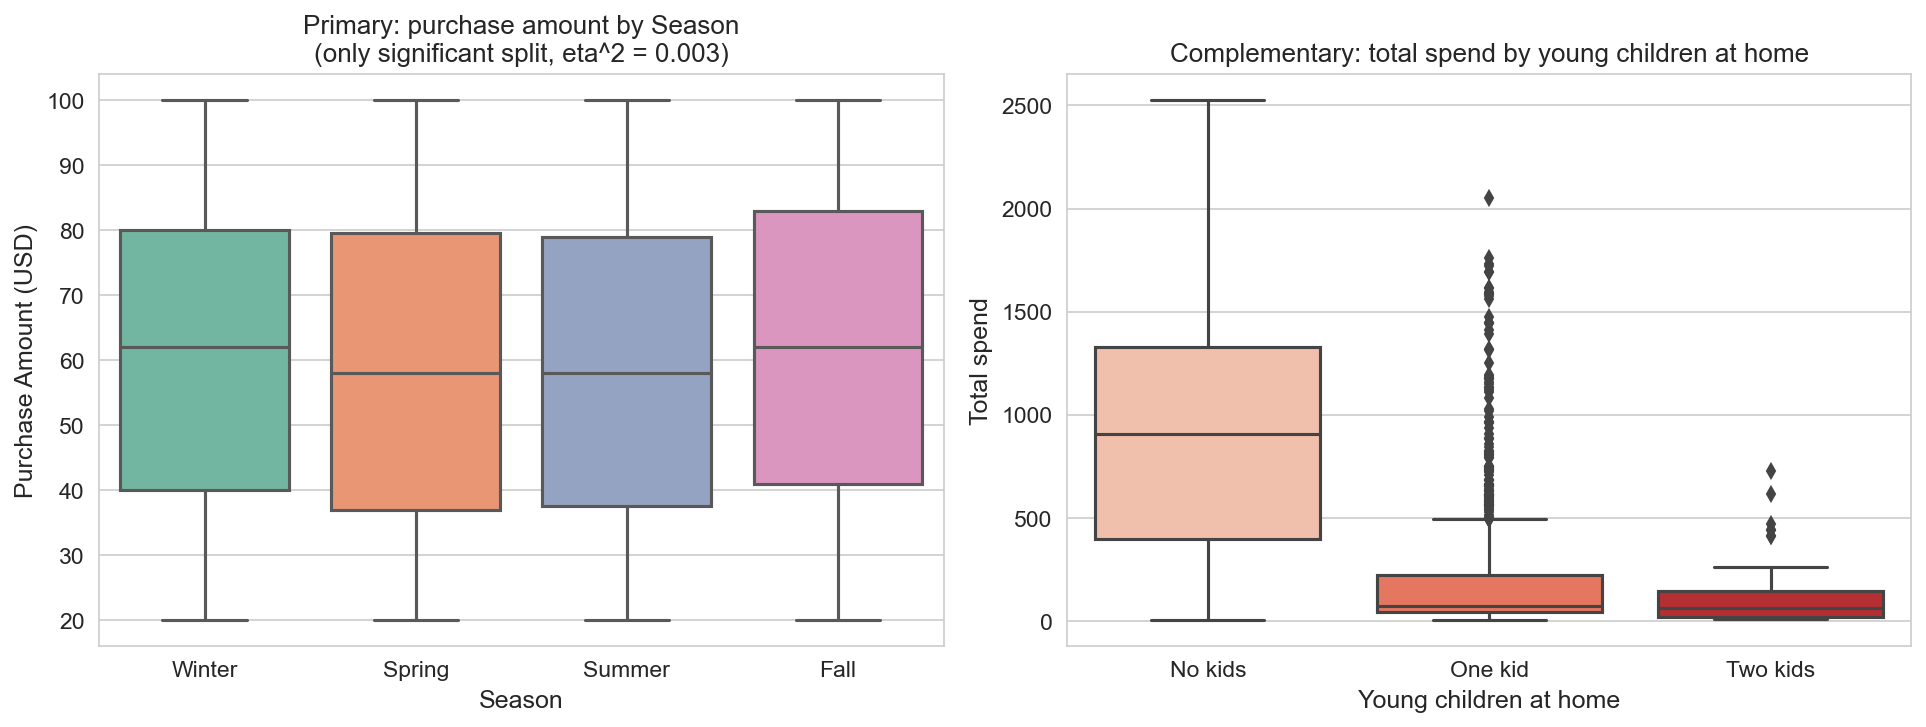

In [14]:
m['Kid_label'] = m['Kidhome'].map({
    0: 'No kids',
    1: 'One kid',
    2: 'Two kids'
})

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.boxplot(
    data=s,
    x='Season',
    y=amt,
    palette='Set2',
    ax=axes[0]
)

axes[0].set_title(
    'Primary: purchase amount by Season\n(only significant split, eta^2 = 0.003)',
    fontsize=12.5
)
axes[0].set_xlabel('Season', fontsize=12)
axes[0].set_ylabel('Purchase Amount (USD)', fontsize=12)

sns.boxplot(
    data=m,
    x='Kid_label',
    y='Spend',
    order=['No kids', 'One kid', 'Two kids'],
    palette='Reds',
    ax=axes[1]
)

axes[1].set_title(
    'Complementary: total spend by young children at home',
    fontsize=12.5
)
axes[1].set_xlabel('Young children at home', fontsize=12)
axes[1].set_ylabel('Total spend', fontsize=12)

for ax in axes:
    ax.tick_params(axis='both', labelsize=11)

plt.tight_layout()
plt.savefig('fig4_boxplots.png', dpi=150, bbox_inches='tight')
plt.close('all')

display(Image('fig4_boxplots.png'))

## 7. RQ2 — Multiple regression

Total spend is modelled on income, household composition and channel purchases. We report
variance inflation factors and a residual check rather than silently correcting violations.

In [15]:
from sklearn.linear_model import LinearRegression

feats = ['Income', 'Kidhome', 'Teenhome', 'Recency',
         'NumCatalogPurchases', 'NumStorePurchases', 'NumWebPurchases']

Xr, yr = m[feats], m['Spend']
lr = LinearRegression().fit(Xr, yr)

r2  = lr.score(Xr, yr)
n, p = Xr.shape
adj = 1 - (1 - r2) * (n - 1) / (n - p - 1)

print(f'R-squared      : {r2:.4f}')
print(f'Adj R-squared  : {adj:.4f}')
print(f'n              : {n}')
print(f'\nintercept     : {lr.intercept_:.2f}')
print(f'\n{"feature":<22}{"coefficient":>14}')
print('-' * 36)
for f, cf in zip(feats, lr.coef_):
    print(f'{f:<22}{cf:>14.4f}')

print('\nVariance inflation factors:')
for f in feats:
    others = [x for x in feats if x != f]
    rj = LinearRegression().fit(m[others], m[f]).score(m[others], m[f])
    print(f'  {f:<22}{1 / (1 - rj):>7.2f}')

R-squared      : 0.7711
Adj R-squared  : 0.7704
n              : 2213

intercept     : -159.69

feature                  coefficient
------------------------------------
Income                        0.0048
Kidhome                    -101.8135
Teenhome                   -149.6270
Recency                       0.3126
NumCatalogPurchases          86.4661
NumStorePurchases            43.1286
NumWebPurchases              34.6270

Variance inflation factors:
  Income                   1.75
  Kidhome                  1.53
  Teenhome                 1.07
  Recency                  1.00
  NumCatalogPurchases      1.91
  NumStorePurchases        1.86
  NumWebPurchases          1.48


R-squared = 0.771 — these seven variables explain about 77% of the variation in total spend,
against an R-squared that would be near zero on the primary dataset. All VIFs are below 2, so
multicollinearity is **not** a problem here; that is itself a result worth reporting.

The income coefficient looks small (0.0048) only because income is measured in dollars:
each additional 1,000 USD of income is associated with about 4.8 USD more spend, holding the
rest constant. Having one young child is associated with about 102 USD less spend, and one
teenager with about 150 USD less.

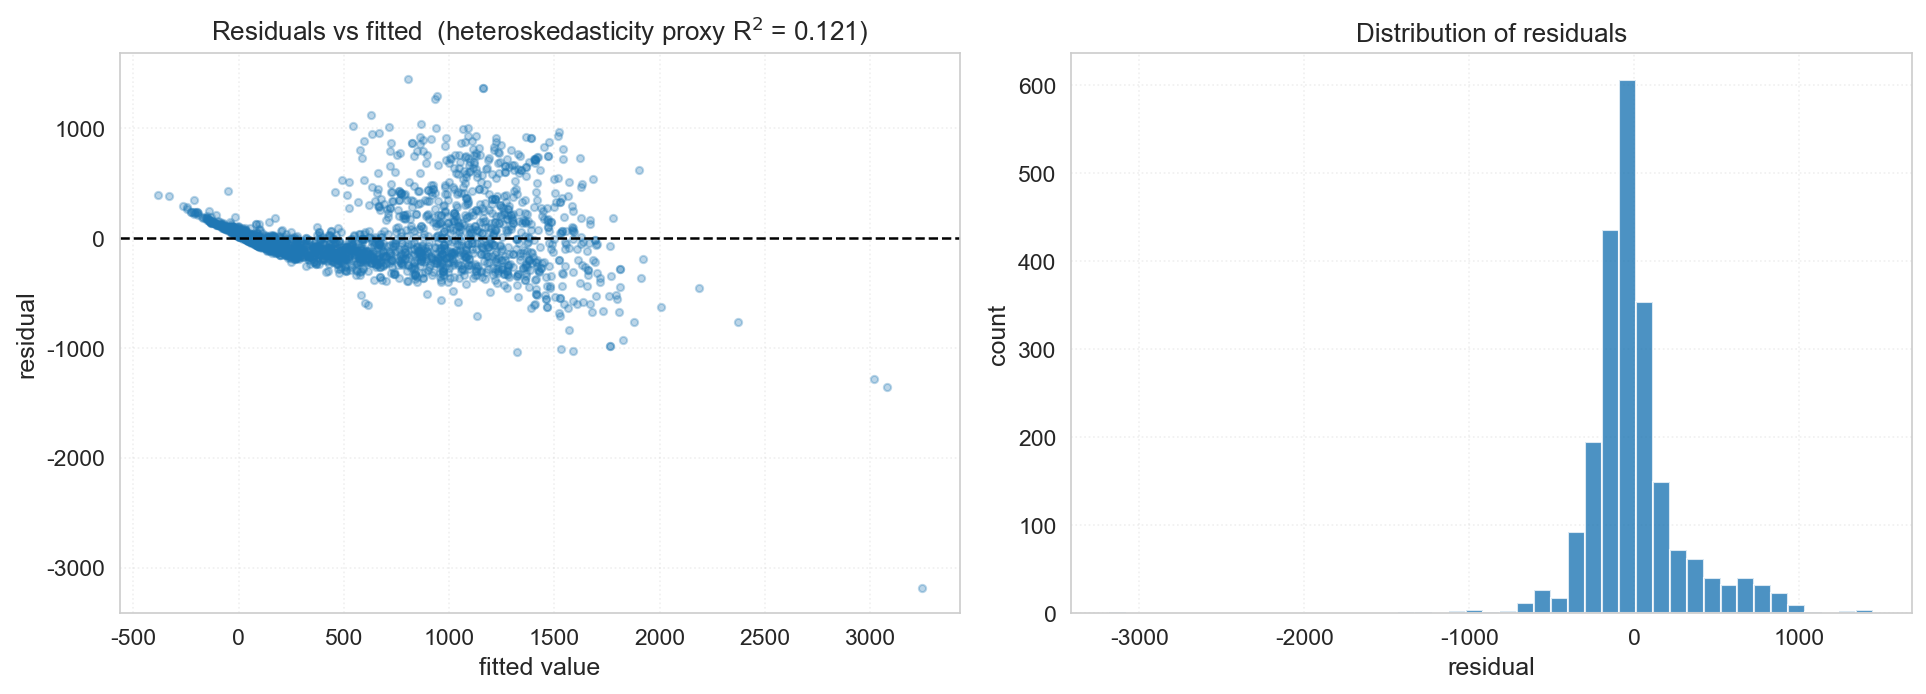

In [16]:
fitted = lr.predict(Xr)
resid  = (yr - fitted).values

het = LinearRegression().fit(fitted.reshape(-1, 1), resid ** 2).score(
          fitted.reshape(-1, 1), resid ** 2)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
axes[0].scatter(fitted, resid, s=12, alpha=.3, c='#1f77b4')
axes[0].axhline(0, ls='--', c='k', lw=1.2)
axes[0].set_xlabel('fitted value', fontsize=12)
axes[0].set_ylabel('residual', fontsize=12)
axes[0].set_title(f'Residuals vs fitted  (heteroskedasticity proxy R$^2$ = {het:.3f})',
                  fontsize=12.5)

axes[1].hist(resid, bins=45, color='#1f77b4', alpha=.8)
axes[1].set_xlabel('residual', fontsize=12)
axes[1].set_ylabel('count', fontsize=12)
axes[1].set_title('Distribution of residuals', fontsize=12.5)

for ax in axes:
    ax.tick_params(labelsize=11)
    ax.grid(ls=':', alpha=.3)
    ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig('fig6_diagnostics.png', dpi=150, bbox_inches='tight')
plt.close('all')
display(Image('fig6_diagnostics.png'))

The residual fan is visible at low fitted values, so mild heteroskedasticity is present and is
reported rather than corrected. Because the goal is explanation of associations rather than
prediction intervals, ordinary least squares remains adequate here.

### 7.1 Sensitivity check — the 666,666 income value

One row carries an implausible income of 666,666. Removing it raises the income-spend correlation
from 0.668 to 0.793, so the headline figure is conservative: the reported result is the *weaker*
of the two. We note this rather than silently choosing the more favourable number.

In [17]:
without_outlier = m[m['Income'] < 600000]
print(f'full sample            n = {len(m):5d}   Income r = {m["Income"].corr(m["Spend"]):.4f}')
print(f'excluding Income>600k  n = {len(without_outlier):5d}   Income r = '
      f'{without_outlier["Income"].corr(without_outlier["Spend"]):.4f}')

full sample            n =  2213   Income r = 0.6675
excluding Income>600k  n =  2212   Income r = 0.7927


## 8. RQ3 — Customer segmentation

K-means on standardised behavioural variables. The elbow curve and silhouette scores are reported
together so the choice of k is argued, not asserted.

In [18]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

cl_cols = ['Income', 'Recency', 'TotalPurchases', 'NumCatalogPurchases',
           'NumStorePurchases', 'NumWebPurchases', 'Age', 'Spend']

Xs = StandardScaler().fit_transform(m[cl_cols])

inertia, sil = [], []
for k in range(2, 8):
    km = KMeans(n_clusters=k, random_state=7, n_init=10).fit(Xs)
    inertia.append(km.inertia_)
    sil.append(silhouette_score(Xs, km.labels_))
    print(f'k = {k}   inertia = {km.inertia_:9.1f}   silhouette = {sil[-1]:.4f}')

k = 2   inertia =   10336.0   silhouette = 0.3741
k = 3   inertia =    9138.6   silhouette = 0.2547
k = 4   inertia =    8379.6   silhouette = 0.1896
k = 5   inertia =    7745.9   silhouette = 0.1870
k = 6   inertia =    7281.4   silhouette = 0.1912
k = 7   inertia =    6822.4   silhouette = 0.1864


Silhouette is highest at k = 2 but the elbow in inertia sits around k = 3-4. We take k = 4:
it keeps enough resolution to be actionable while each segment stays large enough to interpret.

In [19]:
km = KMeans(n_clusters=4, random_state=7, n_init=10).fit(Xs)
m['Cluster'] = km.labels_

prof = m.groupby('Cluster')[
    ['Income', 'Age', 'TotalPurchases', 'NumCatalogPurchases',
     'NumStorePurchases', 'NumWebPurchases', 'Spend', 'Response']
].mean().round(2)
prof['n'] = m.groupby('Cluster').size()

print(f'overall campaign response rate : {m["Response"].mean():.4f}\n')
prof

overall campaign response rate : 0.1505



,Income,Age,TotalPurchases,NumCatalogPurchases,NumStorePurchases,NumWebPurchases,Spend,Response,n
Cluster,,,,,,,,,
0,32931.36,50.15,7.26,0.46,3.01,1.88,79.82,0.14,521
1,58166.60,59.34,19.33,2.61,7.24,6.12,683.29,0.14,610
2,37083.21,54.68,8.44,0.67,3.39,2.25,118.74,0.04,500
3,76321.45,55.39,22.60,6.43,8.88,5.51,1418.52,0.27,582


The four segments differ sharply in value: mean spend runs from about 80 USD to about 1,419 USD.
More usefully for a marketing decision, **campaign response rate ranges from 0.04 to 0.27** —
segment 3 responds at roughly seven times the rate of segment 2, even though segment 2 is not
the lowest-income group. Targeting on income alone would miss this.

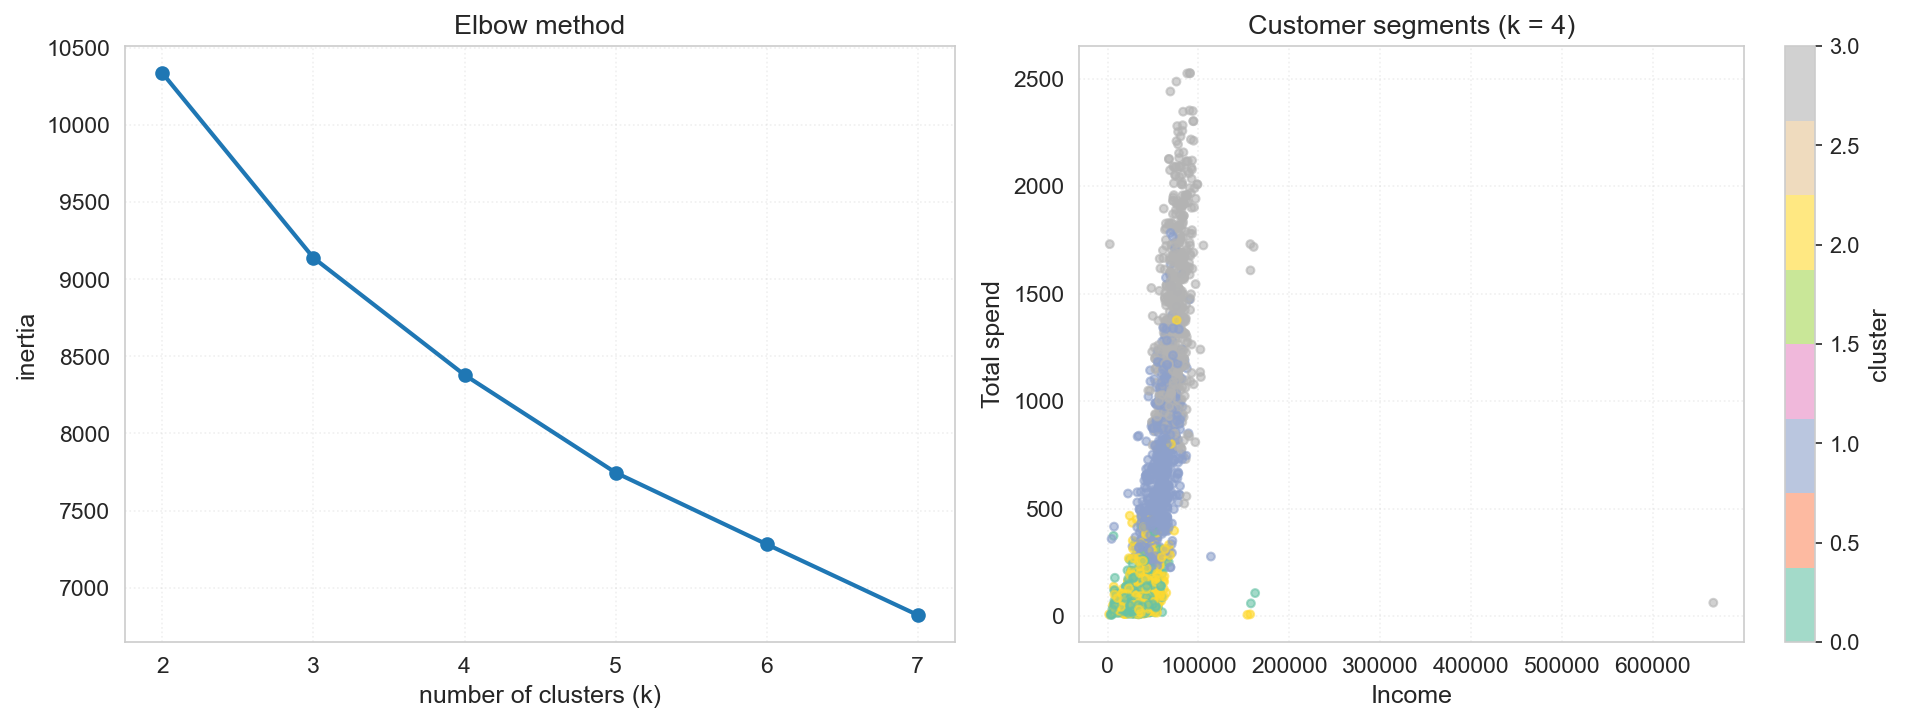

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(range(2, 8), inertia, 'o-', lw=2, color='#1f77b4')
axes[0].set_xlabel('number of clusters (k)', fontsize=12)
axes[0].set_ylabel('inertia', fontsize=12)
axes[0].set_title('Elbow method', fontsize=13)

sc = axes[1].scatter(m['Income'], m['Spend'], c=m['Cluster'],
                     cmap='Set2', s=14, alpha=.6)
axes[1].set_xlabel('Income', fontsize=12)
axes[1].set_ylabel('Total spend', fontsize=12)
axes[1].set_title('Customer segments (k = 4)', fontsize=13)
plt.colorbar(sc, ax=axes[1], label='cluster')

for ax in axes:
    ax.tick_params(labelsize=11)
    ax.grid(ls=':', alpha=.3)
    ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig('fig5_clusters.png', dpi=150, bbox_inches='tight')
plt.close('all')
display(Image('fig5_clusters.png'))

## 9. Summary of findings

| Question | Answer |
|---|---|
| **RQ1** | The primary dataset is effectively signal-free: r = 0.008 / -0.010 / 0.031, and seven of eight ANOVA groupings are non-significant with eta-squared < 0.003. Only Season reaches p = 0.011, with a negligible effect size. |
| **RQ2** | In the complementary dataset, income, catalogue, store and web purchases are positively associated with spend (r = 0.67 / 0.78 / 0.68 / 0.53) and young children negatively (r = -0.56). A seven-variable regression reaches R-squared = 0.771. |
| **RQ3** | Four segments emerge with mean spend from 80 to 1,419 USD and campaign response from 0.04 to 0.27 — a difference that income alone does not explain. |
| **RQ4** | Statistical significance is not evidence of a usable relationship. With n = 3,900 a p-value of 0.011 can accompany an effect size of 0.003, so a dataset should be audited for signal *before* any model is built on it. |

**Limitations.** Both datasets are observational and cross-sectional, so all findings are
associations and no causal claim is made. Cleaning reduced the complementary dataset from 2,240
to 2,213 rows, which is ample for correlation and regression but limits how finely segments can be
split. The flat correlations of the primary dataset are consistent with synthetic generation; this
is reported as a property of the data source, not as a finding about shoppers. Mild
heteroskedasticity is present in the regression and is reported rather than corrected. Both files
are public teaching datasets containing no personally identifiable information.